# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [3]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from pathlib import Path
import re

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [4]:
dataset_name = "Lab_11_QnA_Dataset.csv"
dataset_candidates = [
    Path.cwd() / dataset_name,
    Path.cwd() / "LAB" / "Lab11" / dataset_name,
    Path.cwd() / "First_Term" / "NLP" / "LAB" / "Lab11" / dataset_name,
    Path("/content") / dataset_name,
]
dataset_path = next((path for path in dataset_candidates if path.exists()), None)
if dataset_path is None:
    raise FileNotFoundError(f"Place {dataset_name} next to this notebook or in LAB/Lab11.")

df = pd.read_csv(dataset_path)
required_columns = {"question", "answer_id", "answer"}
if not required_columns.issubset(df.columns):
    raise ValueError(f"CSV must contain these columns: {required_columns}")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
print(df.head())


Number of questions: 168
Number of answer groups: 12
               question  answer_id                answer
0      Do you get hurt?          0  I don't have a body.
1  Do you have fingers?          0  I don't have a body.
2   Do you ever breathe          0  I don't have a body.
3     Do you masticate?          0  I don't have a body.
4     Can you throw up?          0  I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [5]:
# Lowercase, remove punctuation, and split each question into words.
def tokenize_question(question):
    return re.findall(r"[a-z0-9']+", str(question).lower())

df["question"] = df["question"].fillna("").astype(str)
tokenized_questions = [tokenize_question(question) for question in df["question"]]

# 0 is padding and 1 is the unknown-word token.
word_to_id = {"<PAD>": 0, "<UNK>": 1}
for words in tokenized_questions:
    for word in words:
        if word not in word_to_id:
            word_to_id[word] = len(word_to_id)

max_len = max(len(words) for words in tokenized_questions)
X = torch.zeros((len(tokenized_questions), max_len), dtype=torch.long)
for row, words in enumerate(tokenized_questions):
    ids = [word_to_id[word] for word in words]
    if ids:
        X[row, :len(ids)] = torch.tensor(ids, dtype=torch.long)

y = torch.tensor(df["answer_id"].astype(int).values, dtype=torch.long)
print("Vocabulary size:", len(word_to_id))
print("Question tensor shape:", tuple(X.shape))

Vocabulary size: 228
Question tensor shape: (168, 11)


## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [6]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(word_to_id), 16, padding_idx=0)
        self.rnn = nn.RNN(16, 32, batch_first=True)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        outputs, _ = self.rnn(self.emb(x))
        scores = self.att(outputs).squeeze(-1)
        scores = scores.masked_fill(x == 0, -1e9)
        weights = torch.softmax(scores, dim=1)
        context = (outputs * weights.unsqueeze(-1)).sum(dim=1)
        return self.fc(context), weights

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [7]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    optimizer.zero_grad()
    logits, _ = model(X)
    loss = nn.functional.cross_entropy(logits, y)
    loss.backward()
    optimizer.step()

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

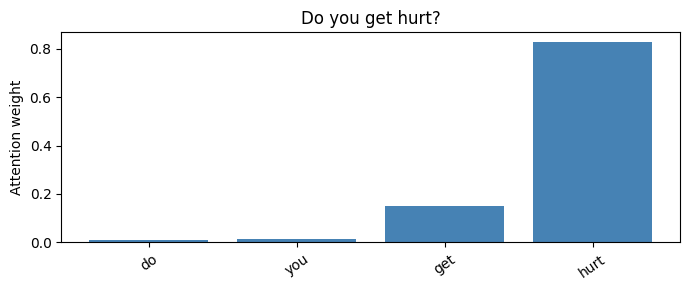

In [8]:
def show_attention(question, ax, title=None):
    words = tokenize_question(question)[:max_len]
    ids = [word_to_id.get(word, word_to_id["<UNK>"]) for word in words]
    ids += [0] * (max_len - len(ids))
    question_tensor = torch.tensor([ids], dtype=torch.long)

    model.eval()
    with torch.no_grad():
        logits, attention = model(question_tensor)

    values = attention[0, :len(words)].tolist()
    ax.bar(words, values, color="steelblue")
    ax.set_title(title or question)
    ax.set_ylabel("Attention weight")
    ax.tick_params(axis="x", rotation=35)
    return words, values, int(logits.argmax(dim=1).item())

question = df["question"].iloc[0]
fig, ax = plt.subplots(figsize=(7, 3))
show_attention(question, ax)
plt.tight_layout()
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

Do you get hurt? -> highest attention: 'hurt' (0.827)
Who programmed you? -> highest attention: 'programmed' (0.702)
What is your purpose? -> highest attention: 'purpose' (0.684)


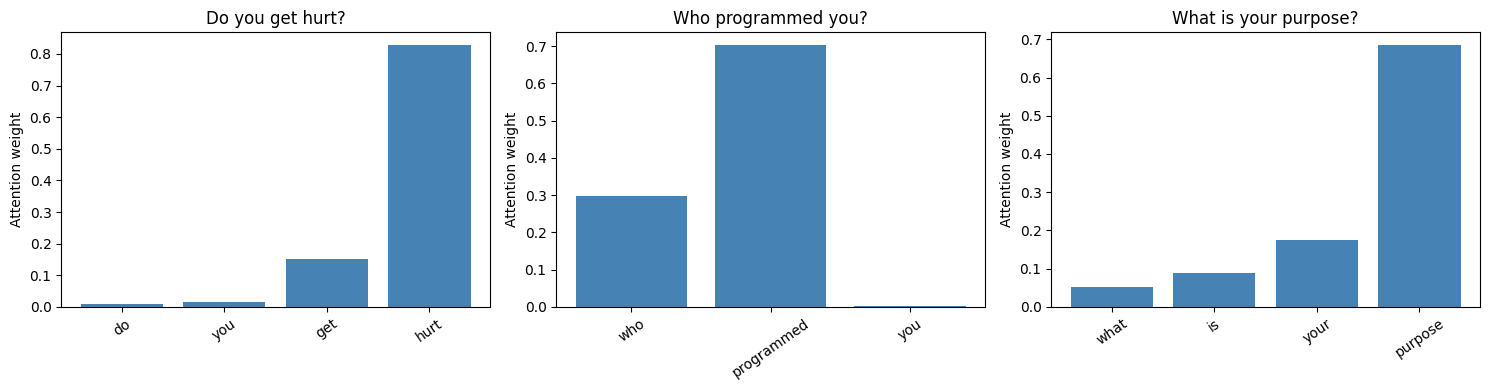

Observation: The highest-weight word is the word this trained model relies on most for its answer.
When it is a meaningful word, such as 'hurt', 'programmed', or 'purpose', the focus is reasonable. Attention shows model focus; by itself, it does not prove human-like understanding.


In [9]:
# Three questions selected from the dataset.
selected_questions = ["Do you get hurt?", "Who programmed you?", "What is your purpose?"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for question, ax in zip(selected_questions, axes):
    words, weights, _ = show_attention(question, ax)
    highest_index = max(range(len(weights)), key=weights.__getitem__)
    print(f"{question} -> highest attention: '{words[highest_index]}' ({weights[highest_index]:.3f})")

plt.tight_layout()
plt.show()

print("Observation: The highest-weight word is the word this trained model relies on most for its answer.")
print("When it is a meaningful word, such as 'hurt', 'programmed', or 'purpose', the focus is reasonable. Attention shows model focus; by itself, it does not prove human-like understanding.")

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

Are you old? -> answer group 1; highest-attention words: ['old', 'are', 'you']
What's your age? -> answer group 1; highest-attention words: ['age', 'your', "what's"]


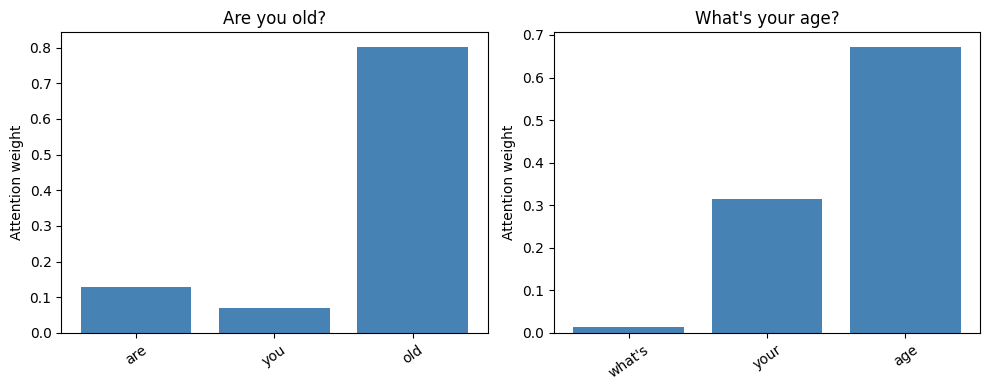

The two questions can receive different word weights because their wording differs. If words such as 'old' and 'age' get high weights, attention is highlighting terms that help map both questions to the same intent.


In [10]:
# These questions have similar meanings and the same answer group in the dataset.
similar_questions = ["Are you old?", "What's your age?"]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for question, ax in zip(similar_questions, axes):
    words, weights, answer_id = show_attention(question, ax)
    top_indices = sorted(range(len(weights)), key=lambda i: weights[i], reverse=True)[:3]
    top_words = [words[i] for i in top_indices]
    print(f"{question} -> answer group {answer_id}; highest-attention words: {top_words}")

plt.tight_layout()
plt.show()

print("The two questions can receive different word weights because their wording differs. If words such as 'old' and 'age' get high weights, attention is highlighting terms that help map both questions to the same intent.")